# CBIS-DDSM Mammography — Multi-Output Clinical Report Model
CLIP vision encoder + 6 classification heads → structured radiologist-style report

**Predicted fields per image:**
- Pathology (BENIGN / MALIGNANT)
- BI-RADS assessment (0–6)
- Subtlety (1–5)
- Breast density (1–4)
- Mass shape
- Mass margins

In [21]:
import os, warnings
os.environ['TRANSFORMERS_OFFLINE'] = '1'
os.environ['HF_DATASETS_OFFLINE'] = '1'
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm
from pathlib import Path
from datetime import datetime
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from transformers import CLIPModel, CLIPProcessor
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, roc_auc_score,
    confusion_matrix, classification_report
)
warnings.filterwarnings('ignore')

# ── GPU setup (RTX 4050 optimised) ───────────────────────────────────────
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.benchmark = True
    print(f"GPU  : {torch.cuda.get_device_name(0)}")
    print(f"VRAM : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
print(f"Device : {DEVICE}")
print(f"PyTorch: {torch.__version__}")

GPU  : NVIDIA GeForce RTX 4050 Laptop GPU
VRAM : 6.4 GB
Device : cuda
PyTorch: 2.6.0+cu124


## 1 — Config

In [22]:
# ── Local project paths (relative — works inside mammography-clip/) ───────
BASE      = './data'
CSV_DIR   = f'{BASE}/csv'
JPEG_ROOT = f'{BASE}/jpeg'
SAVE_DIR  = './output'
os.makedirs(SAVE_DIR, exist_ok=True)
os.makedirs('./new_images', exist_ok=True)

CONFIG = {
    'model_name': 'shawn24/Mammo-CLIP',
    'batch_size'             : 8,       # safe for 6 GB VRAM (RTX 4050)
    'num_epochs'             : 20,  # bumped from 15 to compensate for no 3x caption augmentation
    'lr'                     : 1e-5,
    'weight_decay'           : 0.01,
    'max_length'             : 77,
    'num_workers'            : 0,       # MUST be 0 on Windows
    'patience'               : 2,
    'freeze_vision'          : False,
    'unfreeze_last_n_vision' : 4,
    'k_folds'                : 3,
    'unfreeze_last_n_resnet' : 2   # unfreeze layer3 + layer4
    
}
print("Config:", CONFIG)

Config: {'model_name': 'shawn24/Mammo-CLIP', 'batch_size': 8, 'num_epochs': 20, 'lr': 1e-05, 'weight_decay': 0.01, 'max_length': 77, 'num_workers': 0, 'patience': 2, 'freeze_vision': False, 'unfreeze_last_n_vision': 4, 'k_folds': 3, 'unfreeze_last_n_resnet': 2}


## 2 — Load CSVs

In [23]:
mass_train = pd.read_csv(f'{CSV_DIR}/mass_case_description_train_set.csv')
mass_test  = pd.read_csv(f'{CSV_DIR}/mass_case_description_test_set.csv')
calc_train = pd.read_csv(f'{CSV_DIR}/calc_case_description_train_set.csv')
calc_test  = pd.read_csv(f'{CSV_DIR}/calc_case_description_test_set.csv')

# Normalise column name (calc files use a space, mass files use underscore)
for df in [calc_train, calc_test]:
    df.rename(columns={'breast density': 'breast_density'}, inplace=True)

# Collapse BENIGN_WITHOUT_CALLBACK → BENIGN everywhere
for df in [mass_train, mass_test, calc_train, calc_test]:
    df['pathology'] = df['pathology'].replace('BENIGN_WITHOUT_CALLBACK', 'BENIGN')

print(f"mass_train : {len(mass_train):,} rows")
print(f"mass_test  : {len(mass_test):,} rows")
print(f"calc_train : {len(calc_train):,} rows")
print(f"calc_test  : {len(calc_test):,} rows")
print("\nMass train columns:", list(mass_train.columns))

mass_train : 1,318 rows
mass_test  : 378 rows
calc_train : 1,546 rows
calc_test  : 326 rows

Mass train columns: ['patient_id', 'breast_density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'mass shape', 'mass margins', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path']


## 3 — JPEG path cache

In [24]:
print("Building JPEG path cache...")
jpeg_cache = {}
for uid_folder in os.listdir(JPEG_ROOT):
    full_path = os.path.join(JPEG_ROOT, uid_folder)
    if os.path.isdir(full_path):
        files = [f for f in os.listdir(full_path) if f.endswith('.jpg')]
        if files:
            jpeg_cache[uid_folder] = os.path.join(full_path, files[0])
print(f"Cached {len(jpeg_cache):,} JPEG paths")

def resolve_path(csv_path):
    """Map a DICOM-style CSV path to the actual JPEG on disk via the UID cache."""
    parts = str(csv_path).split('/')
    for idx in [3, 2]:
        if len(parts) > idx:
            result = jpeg_cache.get(parts[idx])
            if result:
                return result
    return None

for name, df in [('mass_train', mass_train), ('mass_test', mass_test),
                 ('calc_train', calc_train),  ('calc_test', calc_test)]:
    found = df['cropped image file path'].apply(resolve_path).notna().sum()
    print(f"  {name:12s}: {found}/{len(df)} paths resolved")

Building JPEG path cache...
Cached 6,774 JPEG paths
  mass_train  : 1318/1318 paths resolved
  mass_test   : 378/378 paths resolved
  calc_train  : 1545/1546 paths resolved
  calc_test   : 326/326 paths resolved


## 4 — Build dataframes with ALL clinical labels

In [25]:
def build_df(df, lesion_type):
    """
    Build a dataframe that keeps ALL clinical label columns needed
    for multi-output prediction, plus the image path.
    """
    density_col = 'breast_density' if 'breast_density' in df.columns else 'breast density'
    records = []

    for _, row in df.iterrows():
        img_path = (resolve_path(row.get('cropped image file path'))
                 or resolve_path(row.get('image file path')))
        if img_path is None:
            continue

        def g(col, default=None):
            v = row.get(col)
            return str(v).strip() if pd.notna(v) else default

        pathology  = g('pathology', 'BENIGN')
        assessment = g('assessment', None)
        subtlety   = g('subtlety',   None)
        density    = g(density_col,  None)
        pid        = g('patient_id', 'unknown')
        laterality = g('left or right breast', 'unspecified')
        view       = g('image view', 'unspecified')
        ab_type    = g('abnormality type', lesion_type)

        # Mass-specific fields
        mass_shape   = g('mass shape',   None) if lesion_type == 'mass' else None
        mass_margins = g('mass margins', None) if lesion_type == 'mass' else None
        calc_type    = g('calc type',    None) if lesion_type == 'calc' else None
        calc_dist    = g('calc distribution', None) if lesion_type == 'calc' else None

        records.append({
            'patient_id'  : pid,
            'image_path'  : img_path,
            'label'       : 1 if pathology == 'MALIGNANT' else 0,
            'pathology'   : pathology,
            'assessment'  : assessment,
            'subtlety'    : subtlety,
            'breast_density': density,
            'mass_shape'  : mass_shape,
            'mass_margins': mass_margins,
            'calc_type'   : calc_type,
            'calc_distribution': calc_dist,
            'laterality'  : laterality,
            'view'        : view,
            'ab_type'     : ab_type,
            'lesion_type' : lesion_type,
        })

    return pd.DataFrame(records)


train_df = pd.concat([build_df(mass_train, 'mass'),
                      build_df(calc_train,  'calc')], ignore_index=True)
test_df  = pd.concat([build_df(mass_test,  'mass'),
                      build_df(calc_test,   'calc')], ignore_index=True)

# Remove conflicting pathology labels for same patient+laterality
def remove_conflicts(df, name):
    mask = (df.groupby(['patient_id', 'laterality'])['pathology']
              .transform('nunique') > 1)
    print(f"  Conflicts removed from {name}: {mask.sum()} rows")
    return df[~mask].reset_index(drop=True)

train_df = remove_conflicts(train_df, 'train')
test_df  = remove_conflicts(test_df,  'test')

print(f"\nTrain : {len(train_df):,} rows | {train_df['patient_id'].nunique()} patients")
print(f"Test  : {len(test_df):,}  rows | {test_df['patient_id'].nunique()} patients")
print(f"\nLabel distribution (train):")
print(train_df['pathology'].value_counts())
print(f"\nSample clinical data:")
print(train_df[['pathology','assessment','subtlety','breast_density','mass_shape','mass_margins']].head(3))

  Conflicts removed from train: 42 rows
  Conflicts removed from test: 14 rows

Train : 2,822 rows | 1242 patients
Test  : 690  rows | 345 patients

Label distribution (train):
pathology
BENIGN       1663
MALIGNANT    1159
Name: count, dtype: int64

Sample clinical data:
   pathology assessment subtlety breast_density  \
0  MALIGNANT          4        4              3   
1  MALIGNANT          4        4              3   
2     BENIGN          4        3              3   

                           mass_shape mass_margins  
0  IRREGULAR-ARCHITECTURAL_DISTORTION   SPICULATED  
1  IRREGULAR-ARCHITECTURAL_DISTORTION   SPICULATED  
2            ARCHITECTURAL_DISTORTION  ILL_DEFINED  


## 5 — Remove train/test patient overlap

In [26]:
overlap = set(train_df['patient_id']) & set(test_df['patient_id'])
if overlap:
    print(f"Removing {len(overlap)} overlapping patients from train_df")
    train_df = train_df[~train_df['patient_id'].isin(overlap)].reset_index(drop=True)

print(f"Train : {len(train_df):,} rows | {train_df['patient_id'].nunique()} patients")
print(f"Test  : {len(test_df):,}  rows | {test_df['patient_id'].nunique()} patients")

Removing 30 overlapping patients from train_df
Train : 2,743 rows | 1212 patients
Test  : 690  rows | 345 patients


In [27]:
import zipfile

with zipfile.ZipFile('radimagenet_resnet50.pth', 'r') as z:
    z.extractall('radimagenet_weights')

print("Extracted.")

Extracted.


## 6 — Fit label encoders on training data

In [28]:
# ── Fixed encoders for ordinal/known-range columns ───────────────────────
PATHOLOGY_MAP  = {'BENIGN': 0, 'MALIGNANT': 1}
ASSESSMENT_MAP = {'0':0,'1':1,'2':2,'3':3,'4':4,'5':5,'6':6}
SUBTLETY_MAP   = {'1':0,'2':1,'3':2,'4':3,'5':4}
DENSITY_MAP    = {'1':0,'2':1,'3':2,'4':3}

# ── Data-driven encoders for free-text categorical columns ────────────────
le_shape   = LabelEncoder()
le_margins = LabelEncoder()
le_calctype = LabelEncoder()
le_calcdist = LabelEncoder()

def safe_fit(le, series):
    """Fit LabelEncoder ignoring None/NaN, add 'unknown' class."""
    vals = [v for v in series.dropna() if v is not None]
    le.fit(list(set(vals)) + ['unknown'])
    return le

safe_fit(le_shape,   train_df['mass_shape'].dropna())
safe_fit(le_margins, train_df['mass_margins'].dropna())
safe_fit(le_calctype, train_df['calc_type'].dropna())
safe_fit(le_calcdist, train_df['calc_distribution'].dropna())

def encode_label(le, val, fallback=-1):
    """Encode a single value; return fallback if missing."""
    if val is None or (isinstance(val, float) and np.isnan(val)):
        return fallback
    try:
        return int(le.transform([str(val)])[0])
    except ValueError:
        try:
            return int(le.transform(['unknown'])[0])
        except:
            return fallback

N_SHAPE   = len(le_shape.classes_)
N_MARGINS = len(le_margins.classes_)
N_CALCTYPE = len(le_calctype.classes_)
N_CALCDIST = len(le_calcdist.classes_)

print(f"Mass shape classes   ({N_SHAPE})  : {list(le_shape.classes_)}")
print(f"Mass margin classes  ({N_MARGINS}): {list(le_margins.classes_)}")
print(f"Calc type classes    ({N_CALCTYPE}): {list(le_calctype.classes_[:5])}...")
print(f"Calc distrib classes ({N_CALCDIST}): {list(le_calcdist.classes_)}")

Mass shape classes   (19)  : [np.str_('ARCHITECTURAL_DISTORTION'), np.str_('ASYMMETRIC_BREAST_TISSUE'), np.str_('FOCAL_ASYMMETRIC_DENSITY'), np.str_('IRREGULAR'), np.str_('IRREGULAR-ARCHITECTURAL_DISTORTION'), np.str_('IRREGULAR-FOCAL_ASYMMETRIC_DENSITY'), np.str_('LOBULATED'), np.str_('LOBULATED-ARCHITECTURAL_DISTORTION'), np.str_('LOBULATED-IRREGULAR'), np.str_('LOBULATED-LYMPH_NODE'), np.str_('LOBULATED-OVAL'), np.str_('LYMPH_NODE'), np.str_('OVAL'), np.str_('OVAL-LYMPH_NODE'), np.str_('ROUND'), np.str_('ROUND-IRREGULAR-ARCHITECTURAL_DISTORTION'), np.str_('ROUND-LOBULATED'), np.str_('ROUND-OVAL'), np.str_('unknown')]
Mass margin classes  (16): [np.str_('CIRCUMSCRIBED'), np.str_('CIRCUMSCRIBED-ILL_DEFINED'), np.str_('CIRCUMSCRIBED-MICROLOBULATED'), np.str_('CIRCUMSCRIBED-OBSCURED'), np.str_('ILL_DEFINED'), np.str_('ILL_DEFINED-SPICULATED'), np.str_('MICROLOBULATED'), np.str_('MICROLOBULATED-ILL_DEFINED'), np.str_('MICROLOBULATED-ILL_DEFINED-SPICULATED'), np.str_('MICROLOBULATED-SPICU

## 7 — Multi-output model architecture

CLIP vision encoder (frozen except last 4 layers) + 6 independent classification heads:
- `head_pathology` → BENIGN / MALIGNANT
- `head_assessment` → BI-RADS 0–6
- `head_subtlety` → 1–5
- `head_density` → 1–4
- `head_shape` → mass shape categories
- `head_margins` → mass margin categories

In [29]:
import torchvision.models as tv_models
from torchvision import transforms
class MammographyAugment:
    """
    Mammography-specific augmentation.
    - Removed saturation/hue (useless on grayscale mammograms)
    - Added shear (mimics compression paddle variation)
    - Added gaussian noise (mimics detector noise)
    - Added gamma correction (mimics exposure variation)
    """
    def __init__(self):
        self.geometric = transforms.Compose([
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomVerticalFlip(p=0.3),
            transforms.RandomRotation(degrees=20),
            transforms.RandomResizedCrop(224, scale=(0.85, 1.0)),
            transforms.RandomAffine(
                degrees=0,
                translate=(0.08, 0.08),
                shear=5,              # mimics tissue compression variation
            ),
        ])
        self.intensity = transforms.Compose([
            transforms.ColorJitter(
                brightness=0.35,
                contrast=0.45,
                saturation=0.0,       # removed — no effect on grayscale
                hue=0.0,              # removed — no effect on grayscale
            ),
        ])

    def gaussian_noise(self, img, std=0.015):
        tensor = TF.to_tensor(img)
        noise  = torch.randn_like(tensor) * std
        tensor = torch.clamp(tensor + noise, 0.0, 1.0)
        return TF.to_pil_image(tensor)

    def random_gamma(self, img):
        gamma  = random.uniform(0.8, 1.25)
        tensor = TF.to_tensor(img)
        tensor = torch.clamp(tensor ** gamma, 0.0, 1.0)
        return TF.to_pil_image(tensor)

    def __call__(self, img):
        img = self.geometric(img)
        img = self.intensity(img)
        if random.random() < 0.5:
            img = self.gaussian_noise(img)
        if random.random() < 0.4:
            img = self.random_gamma(img)
        return img



# ── Image preprocessing — replaces CLIPProcessor ──────────────────────────
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

base_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

train_aug = MammographyAugment()  # from cell-8 — returns a PIL image


class MammographyReportModel(nn.Module):
    def __init__(self, n_shape, n_margins, n_calctype, n_calcdist,
                 radimagenet_weights_path=None):
        super().__init__()
        resnet = tv_models.resnet50(weights=None)

        # Build backbone as nn.Sequential FIRST — the RadImageNet checkpoint
        # keys (backbone.0, backbone.1, backbone.4...) match this structure directly
        self.backbone = nn.Sequential(*list(resnet.children())[:-1])
        hidden = 2048

        if radimagenet_weights_path:
            raw_state_dict = torch.load(radimagenet_weights_path,
                                         map_location='cpu', weights_only=True)
            # Strip "backbone." prefix to match self.backbone's own key naming
            state_dict = {
                k[len('backbone.'):]: v
                for k, v in raw_state_dict.items()
                if k.startswith('backbone.')
            }
            missing, unexpected = self.backbone.load_state_dict(state_dict, strict=False)
            print(f"  Loaded RadImageNet weights into backbone")
            print(f"  Missing keys   : {len(missing)}")
            print(f"  Unexpected keys: {len(unexpected)}")

        self.dropout           = nn.Dropout(0.3)
        self.visual_projection = nn.Linear(hidden, 512)

        self.head_pathology   = nn.Linear(512, 2)
        self.head_assessment  = nn.Linear(512, 7)
        self.head_subtlety    = nn.Linear(512, 5)
        self.head_density     = nn.Linear(512, 4)
        self.head_shape       = nn.Linear(512, n_shape)
        self.head_margins     = nn.Linear(512, n_margins)

        # Freeze everything first
        for p in self.backbone.parameters():
            p.requires_grad = False

        # Unfreeze last N resnet stages (layer1..layer4 are indices 4-7 in children)
        resnet_layers = [self.backbone[6], self.backbone[7]]  # layer3, layer4 only

        N = CONFIG['unfreeze_last_n_resnet']
        for layer in resnet_layers[-N:]:
            for p in layer.parameters():
                p.requires_grad = True
    def get_embedding(self, pixel_values):
        features = self.backbone(pixel_values).flatten(1)  # (B, 2048)
        emb = self.visual_projection(features)
        return self.dropout(emb)  # (B, 512)

    def forward(self, pixel_values):
        emb = self.get_embedding(pixel_values)
        return {
            'pathology'  : self.head_pathology(emb),
            'assessment' : self.head_assessment(emb),
            'subtlety'   : self.head_subtlety(emb),
            'density'    : self.head_density(emb),
            'shape'      : self.head_shape(emb),
            'margins'    : self.head_margins(emb),
        }
    def train(self, mode=True):
        super().train(mode)
        if mode:
            N = CONFIG['unfreeze_last_n_resnet']
            resnet_layers = [self.backbone[6], self.backbone[7]]  # layer3, layer4 only
            unfrozen_modules = set()
            for layer in resnet_layers[-N:]:
                for m in layer.modules():
                    unfrozen_modules.add(id(m))

        # Freeze BN only if it's NOT inside an unfrozen stage
            for m in self.backbone.modules():
                if isinstance(m, nn.BatchNorm2d):
                    if id(m) not in unfrozen_modules:
                        m.eval()
        return self


def build_model():
    model = MammographyReportModel(
        n_shape=N_SHAPE,
        n_margins=N_MARGINS,
        n_calctype=N_CALCTYPE,
        n_calcdist=N_CALCDIST,
        radimagenet_weights_path='radimagenet_weights/RadImageNet_pytorch/ResNet50.pt',
    )
    return model.to(DEVICE)


def build_optimizer(model):
    resnet_layers = [model.backbone[6], model.backbone[7]]  # layer3, layer4 only
    N = CONFIG['unfreeze_last_n_resnet']
    unfrozen_backbone = [
        p for layer in resnet_layers[-N:]
        for p in layer.parameters() if p.requires_grad
    ]
    return AdamW([
        {'params': unfrozen_backbone,                             'lr': CONFIG['lr'] * 0.1},
        {'params': model.visual_projection.parameters(),         'lr': CONFIG['lr']},        # was *5
        {'params': model.head_pathology.parameters(),            'lr': CONFIG['lr'] * 2},    # was *10
        {'params': model.head_assessment.parameters(),           'lr': CONFIG['lr'] * 2},
        {'params': model.head_subtlety.parameters(),             'lr': CONFIG['lr'] * 2},
        {'params': model.head_density.parameters(),              'lr': CONFIG['lr'] * 2},
        {'params': model.head_shape.parameters(),                'lr': CONFIG['lr'] * 2},
        {'params': model.head_margins.parameters(),              'lr': CONFIG['lr'] * 2},
    ], weight_decay=CONFIG['weight_decay'])


print("Model architecture ready.")
_tmp = build_model()
total = sum(p.numel() for p in _tmp.parameters())
train_params = sum(p.numel() for p in _tmp.parameters() if p.requires_grad)
print(f"Total params   : {total:,}")
print(f"Trainable      : {train_params:,}")
del _tmp
torch.cuda.empty_cache()

Model architecture ready.
  Loaded RadImageNet weights into backbone
  Missing keys   : 0
  Unexpected keys: 0
Total params   : 24,584,309
Trainable      : 23,139,381


In [30]:
import os
size = os.path.getsize('radimagenet_resnet50.pth')
print(f"File size: {size / 1e6:.2f} MB")

with open('radimagenet_resnet50.pth', 'rb') as f:
    head = f.read(200)
print(head)
import zipfile

with zipfile.ZipFile('radimagenet_resnet50.pth', 'r') as z:
    names = z.namelist()
    for n in names:
        print(n)

File size: 194.85 MB
b'PK\x03\x04\x14\x00\x00\x00\x08\x00zm;W\x9b\xf9\xbcc\xa7\x07\x91\x01\xd7\x82\xb1\x01"\x00\x00\x00RadImageNet_pytorch/DenseNet121.pt\x9c\x9cw|\x14\xc5\xfb\xc7\xb3%\x04B\xef\x1dB\x0f*p\xbd(jD\xc4\x12\x108,\x11K\x08I$\x91\x900O\x16\x10\x1bX\xa2bE\xb1\xd7\xd8{\xef=\xf6\xde{\x8f\xbd\xf7\xde\x7f\xb7\xcf\xcc>sss\xaf|w\x7f\xfc\x81\x97\x18\xf6\xfd\xde\x99\xe73\x9f\xf3u\x8b\x0b*-\xbb\xa8\xa8{\xf7"\xedW\xbf\xa2\x01E5P\xdb\xd0\xb8\xba~F]\x8dS3}\xe5\xf2\xa69\xb3\xfa\x14-V~\xad7kk[\x9a\x9a\xeak\x9d\xc6\x96\xe6\xd6\xd2\xf9'
RadImageNet_pytorch/DenseNet121.pt
RadImageNet_pytorch/InceptionV3.pt
RadImageNet_pytorch/ResNet50.pt


## 8 — Dataset & DataLoader (multi-label)

In [31]:
import os
print(os.listdir("D:/BreastCancer/mammo-clip"))

[]


In [32]:

# Stronger augmentation to compensate for single-caption dataset (original used 3x captions)
from torchvision import transforms
import torchvision.transforms.functional as TF
import random



class MammographyDataset(Dataset):
    """
    Returns pixel_values + all 6 clinical label tensors.
    Labels missing in the CSV are encoded as -1 (ignored by CrossEntropyLoss).
    """
    def __init__(self, df,augment=False):
        self.df        = df.reset_index(drop=True)
        self.augment   = augment

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        try:
            image = Image.open(row['image_path']).convert('RGB')
            if self.augment:
                image = train_aug(image)
        except Exception:
            image = Image.new('RGB', (224, 224), color=128)

        pixel_values = base_transform(image)
        def enc_fixed(val, mapping):
            if val is None or (isinstance(val, float) and np.isnan(val)):
                return torch.tensor(-1, dtype=torch.long)
            key = str(int(float(val)))  # '4.0' → '4'
            return torch.tensor(mapping.get(key, -1), dtype=torch.long)

        def enc_str(val, mapping):
            """For string-keyed maps like PATHOLOGY_MAP."""
            if val is None or (isinstance(val, float) and np.isnan(val)):
                return torch.tensor(-1, dtype=torch.long)
            return torch.tensor(mapping.get(str(val), -1), dtype=torch.long)

        def enc_fixed(val, mapping):
            if val is None or (isinstance(val, float) and np.isnan(val)):
                return torch.tensor(-1, dtype=torch.long)
            key = str(int(float(val)))  # '4.0' → '4'
            return torch.tensor(mapping.get(key, -1), dtype=torch.long)

        def enc_le(le, val):
            return torch.tensor(encode_label(le, val), dtype=torch.long)

        return {
    'pixel_values': pixel_values,
    'label'       : torch.tensor(row['label'], dtype=torch.long),
    'pathology'   : enc_str(row.get('pathology'),      PATHOLOGY_MAP),   # ← enc_str, not enc_fixed
    'assessment'  : enc_fixed(row.get('assessment'),   ASSESSMENT_MAP),  # numeric '4.0' → '4'
    'subtlety'    : enc_fixed(row.get('subtlety'),     SUBTLETY_MAP),    # numeric
    'density'     : enc_fixed(row.get('breast_density'), DENSITY_MAP),   # numeric
    'shape'       : enc_le(le_shape,   row.get('mass_shape')),
    'margins'     : enc_le(le_margins, row.get('mass_margins')),
}


def make_loaders(df_train_fold, df_val_fold):
    class_counts  = df_train_fold['label'].value_counts().sort_index().values
    class_weights = 1.0 / class_counts
    sample_weights = [class_weights[l] for l in df_train_fold['label']]
    sampler = WeightedRandomSampler(sample_weights, len(sample_weights), replacement=True)

    train_loader = DataLoader(
        MammographyDataset(df_train_fold, augment=True),
        batch_size=CONFIG['batch_size'], sampler=sampler,
        num_workers=CONFIG['num_workers'], pin_memory=True, drop_last=True
    )
    val_loader = DataLoader(
        MammographyDataset(df_val_fold),
        batch_size=CONFIG['batch_size'], shuffle=False,
        num_workers=CONFIG['num_workers'], pin_memory=True
    )
    return train_loader, val_loader


test_loader = DataLoader(
    MammographyDataset(test_df),
    batch_size=CONFIG['batch_size'], shuffle=False,
    num_workers=CONFIG['num_workers'], pin_memory=True
)
print(f"Test batches : {len(test_loader)}")

Test batches : 87


## 9 — Loss, training & evaluation helpers

In [33]:
print("Model architecture ready.")
_tmp = build_model()
total = sum(p.numel() for p in _tmp.parameters())
train_params = sum(p.numel() for p in _tmp.parameters() if p.requires_grad)
print(f"Total params   : {total:,}")
print(f"Trainable      : {train_params:,}")
del _tmp
torch.cuda.empty_cache()

Model architecture ready.
  Loaded RadImageNet weights into backbone
  Missing keys   : 0
  Unexpected keys: 0
Total params   : 24,584,309
Trainable      : 23,139,381


In [34]:
import math

# ── Ordinal soft-label loss ───────────────────────────────────────────────
class OrdinalSoftLabelLoss(nn.Module):
    def __init__(self, num_classes: int, sigma: float = 0.9):
        super().__init__()
        self.num_classes = num_classes
        self.sigma       = sigma
        self.register_buffer('classes', torch.arange(num_classes, dtype=torch.float32))

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        t        = targets.float().unsqueeze(1)
        c        = self.classes.unsqueeze(0)
        soft     = torch.exp(-0.5 * ((c - t) / self.sigma) ** 2)
        soft     = soft / soft.sum(dim=1, keepdim=True)
        log_prob = F.log_softmax(logits, dim=1)
        return -(soft * log_prob).sum(dim=1).mean()


# ── Loss functions ────────────────────────────────────────────────────────
MALIGNANT_WEIGHT   = 1.0
path_class_weights = torch.tensor([1.0, MALIGNANT_WEIGHT], dtype=torch.float32).to(DEVICE)
ce_pathology       = nn.CrossEntropyLoss(weight=path_class_weights)
ce_assessment      = OrdinalSoftLabelLoss(num_classes=7, sigma=0.9).to(DEVICE)
ce_subtlety        = OrdinalSoftLabelLoss(num_classes=5, sigma=0.9).to(DEVICE)
ce_density         = OrdinalSoftLabelLoss(num_classes=4, sigma=0.9).to(DEVICE)
ce_shape           = nn.CrossEntropyLoss(label_smoothing=0.1)
ce_margins         = nn.CrossEntropyLoss(label_smoothing=0.1)

HEAD_LOSS_FN = {
    'pathology'  : ce_pathology,
    'assessment' : ce_assessment,
    'subtlety'   : ce_subtlety,
    'density'    : ce_density,
    'shape'      : ce_shape,
    'margins'    : ce_margins,
}

HEAD_WEIGHTS = {
    'pathology'  : 2.0,
    'assessment' : 1.5,
    'subtlety'   : 0.5,
    'density'    : 1.0,
    'shape'      : 1.0,
    'margins'    : 1.0,
}


# ── Multi-head loss ───────────────────────────────────────────────────────
def compute_loss(outputs, batch):
    total  = 0.0
    losses = {}
    for head, weight in HEAD_WEIGHTS.items():
        targets = batch[head].to(DEVICE)
        valid   = targets != -1
        if valid.any():
            l            = HEAD_LOSS_FN[head](outputs[head][valid], targets[valid])
            losses[head] = l.item()
            total       += weight * l
        else:
            losses[head] = float('nan')
    return total, losses


# ── Training / validation epoch ───────────────────────────────────────────
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, n = 0.0, 0
    ctx = torch.enable_grad() if training else torch.no_grad()

    with ctx:
        for batch in tqdm(loader, desc='  train' if training else '  val  ', leave=False):
            pv      = batch['pixel_values'].to(DEVICE)
            outputs = model(pv)
            loss, _ = compute_loss(outputs, batch)

            if training:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

            loss_val = loss.item()
            if not math.isnan(loss_val):
                total_loss += loss_val
                n          += 1

    return total_loss / max(n, 1)


# ── Temperature scaling (post-hoc calibration) ───────────────────────────
def find_temperature(model, loader, n_bins=10):
    """
    Learn a single temperature scalar T on the validation set.
    Minimises NLL of calibrated probabilities: softmax(logits / T).
    Returns the optimal T (float).
    T > 1 → flatten distribution (model was overconfident)
    T < 1 → sharpen distribution (model was underconfident)
    """
    model.eval()
    all_logits, all_labels = [], []

    with torch.no_grad():
        for batch in loader:
            pv     = batch['pixel_values'].to(DEVICE)
            logits = model(pv)['pathology']
            labels = batch['pathology']
            valid  = labels != -1
            if valid.any():
                all_logits.append(logits[valid].cpu())
                all_labels.append(labels[valid].cpu())

    all_logits = torch.cat(all_logits)   # (N, 2)
    all_labels = torch.cat(all_labels)   # (N,)

    # Optimise T via LBFGS — standard calibration approach
    temperature = nn.Parameter(torch.ones(1) * 1.5)
    optimizer   = torch.optim.LBFGS([temperature], lr=0.01, max_iter=100)
    nll_loss    = nn.CrossEntropyLoss()

    def eval_t():
        optimizer.zero_grad()
        loss = nll_loss(all_logits / temperature.clamp(min=0.1), all_labels)
        loss.backward()
        return loss

    optimizer.step(eval_t)
    return temperature.item()


# ── ECE (Expected Calibration Error) ─────────────────────────────────────
def compute_ece(probs, labels, n_bins=10):
    """
    Splits predictions into n_bins by confidence, computes
    |mean_confidence - fraction_positive| weighted by bin size.
    Perfect calibration = ECE of 0.
    """
    probs  = np.array(probs)
    labels = np.array(labels)
    bins   = np.linspace(0.0, 1.0, n_bins + 1)
    ece    = 0.0
    n      = len(probs)

    for i in range(n_bins):
        mask = (probs >= bins[i]) & (probs < bins[i+1])
        if mask.sum() == 0:
            continue
        bin_conf = probs[mask].mean()
        bin_acc  = labels[mask].mean()
        ece     += (mask.sum() / n) * abs(bin_conf - bin_acc)

    return ece


# ── Reliability diagram ───────────────────────────────────────────────────
def reliability_diagram(probs, labels, title='Reliability Diagram', n_bins=10, save_path=None):
    """
    Plots mean predicted probability vs actual fraction positive per bin.
    Perfect calibration = diagonal line.
    """
    probs  = np.array(probs)
    labels = np.array(labels)
    bins   = np.linspace(0.0, 1.0, n_bins + 1)
    bin_centres, bin_accs, bin_counts = [], [], []

    for i in range(n_bins):
        mask = (probs >= bins[i]) & (probs < bins[i+1])
        if mask.sum() == 0:
            continue
        bin_centres.append(probs[mask].mean())
        bin_accs.append(labels[mask].mean())
        bin_counts.append(mask.sum())

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Reliability curve
    ax = axes[0]
    ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration', linewidth=1.5)
    ax.bar(bin_centres, bin_accs, width=0.08, alpha=0.6,
           color='steelblue', edgecolor='navy', label='Model')
    ax.set_xlabel('Mean predicted probability')
    ax.set_ylabel('Fraction of MALIGNANT cases')
    ax.set_title(f'{title}\nECE = {compute_ece(probs, labels, n_bins):.4f}')
    ax.legend()
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)

    # Confidence histogram
    ax2 = axes[1]
    ax2.hist(probs, bins=20, color='steelblue', edgecolor='navy', alpha=0.7)
    ax2.axvline(x=0.5, color='red', linestyle='--', label='Threshold 0.5')
    ax2.set_xlabel('Predicted P(MALIGNANT)')
    ax2.set_ylabel('Count')
    ax2.set_title('Confidence Distribution')
    ax2.legend()

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


# ── TTA evaluate ─────────────────────────────────────────────────────────
@torch.no_grad()
def evaluate_tta(model, loader, split_name='eval', threshold=0.4,
                 n_augments=5, temperature=1.0):
    """
    Test-Time Augmentation: runs each image through n_augments
    augmented versions, averages softmax probabilities before
    thresholding. Typically gives +0.01-0.02 AUC at no training cost.
    Uses the same train_aug pipeline.
    """
    model.eval()
    all_true_path, all_prob_path = [], []

    for batch in tqdm(loader, desc=f'  TTA ({split_name})', leave=False):
        labels = batch['pathology'].numpy()
        valid  = labels != -1
        if not valid.any():
            continue

        # Accumulate probabilities across augmented versions
        aug_probs = []
        raw_images = batch.get('raw_image')  # see note below
        for _ in range(n_augments):
            pv_list = []
            for img in raw_images:
                aug = train_aug(img)
                pv_list.append(base_transform(aug))
            pv = torch.stack(pv_list).to(DEVICE)
            logits = model(pv)['pathology']
            probs = F.softmax(logits / temperature, dim=-1).cpu().numpy()
            aug_probs.append(probs[valid, 1])

        mean_probs = np.mean(aug_probs, axis=0)
        all_prob_path.extend(mean_probs)
        all_true_path.extend(labels[valid])

    all_prob_path = np.array(all_prob_path)
    all_true_path = np.array(all_true_path)
    all_pred_path = (all_prob_path >= threshold).astype(int)

    auc         = roc_auc_score(all_true_path, all_prob_path)
    cm          = confusion_matrix(all_true_path, all_pred_path)
    tn, fp, fn, tp = cm.ravel()
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    precision   = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    f1          = (2 * precision * sensitivity / (precision + sensitivity)
                   if (precision + sensitivity) > 0 else 0.0)
    ece         = compute_ece(all_prob_path, all_true_path)

    print(f"\n  [{split_name}] TTA (n={n_augments})  threshold={threshold}  T={temperature:.3f}")
    print(f"  {'─'*52}")
    print(f"  ROC-AUC           : {auc:.4f}")
    print(f"  ECE               : {ece:.4f}  ← 0=perfect calibration")
    print(f"  Sensitivity/Recall: {sensitivity*100:.2f}%")
    print(f"  Precision         : {precision*100:.2f}%")
    print(f"  F1-score          : {f1*100:.2f}%")
    print(f"  Specificity       : {specificity*100:.2f}%")
    print(f"  Confusion Matrix  : TN={tn}  FP={fp}  FN={fn}  TP={tp}")

    return {
        'auc': auc, 'ece': ece, 'sensitivity': sensitivity,
        'precision': precision, 'f1': f1, 'specificity': specificity,
        'probs': all_prob_path.tolist(), 'labels': all_true_path.tolist(),
        'preds': all_pred_path.tolist(),
    }


# ── Standard evaluate (unchanged interface + temperature + ECE) ──────────
@torch.no_grad()
def evaluate(model, loader, split_name='eval', threshold=0.4, temperature=1.0):
    model.eval()
    all_true_path, all_prob_path = [], []
    all_pred = {k: [] for k in HEAD_WEIGHTS}
    all_true = {k: [] for k in HEAD_WEIGHTS}

    for batch in tqdm(loader, desc=f'  eval ({split_name})', leave=False):
        pv      = batch['pixel_values'].to(DEVICE)
        outputs = model(pv)

        logits = outputs['pathology']
        probs  = F.softmax(logits / temperature, dim=-1).cpu().numpy()
        labels = batch['pathology'].numpy()
        valid  = labels != -1
        if valid.any():
            all_prob_path.extend(probs[valid, 1])
            all_true_path.extend(labels[valid])

        for head in HEAD_WEIGHTS:
            pred_h = outputs[head].cpu().argmax(dim=-1).numpy()
            true_h = batch[head].numpy()
            v      = true_h != -1
            if v.any():
                all_pred[head].extend(pred_h[v])
                all_true[head].extend(true_h[v])

    if not all_true_path:
        return {'acc': 0, 'auc': 0, 'preds': [], 'labels': [], 'probs': []}

    all_prob_path = np.array(all_prob_path)
    all_true_path = np.array(all_true_path)
    all_pred_path = (all_prob_path >= threshold).astype(int)

    acc  = accuracy_score(all_true_path, all_pred_path)
    auc  = roc_auc_score(all_true_path, all_prob_path)
    cm   = confusion_matrix(all_true_path, all_pred_path)
    tn, fp, fn, tp = cm.ravel()
    ece  = compute_ece(all_prob_path, all_true_path)

    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    precision   = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    f1          = (2 * precision * sensitivity / (precision + sensitivity)
                   if (precision + sensitivity) > 0 else 0.0)

    print(f"\n  [{split_name}] Pathology  (threshold={threshold}  T={temperature:.3f})")
    print(f"  {'─'*52}")
    print(f"  Accuracy          : {acc*100:.2f}%")
    print(f"  ROC-AUC           : {auc:.4f}")
    print(f"  ECE               : {ece:.4f}  ← 0=perfect calibration")
    print(f"  ── MALIGNANT ──────────────────────────────────")
    print(f"  Sensitivity/Recall: {sensitivity*100:.2f}%   ← catch cancers")
    print(f"  Precision         : {precision*100:.2f}%   ← of predicted MAL, how many real")
    print(f"  F1-score          : {f1*100:.2f}%")
    print(f"  ── BENIGN ─────────────────────────────────────")
    print(f"  Specificity       : {specificity*100:.2f}%   ← avoid false alarms")
    print(f"  {'─'*52}")
    print(f"  Confusion Matrix  : TN={tn}  FP={fp}  FN={fn}  TP={tp}")
    print(classification_report(all_true_path, all_pred_path,
                                target_names=['BENIGN', 'MALIGNANT'], digits=4))

    print("  Per-head accuracy:")
    for head in HEAD_WEIGHTS:
        if all_true[head]:
            h_acc = accuracy_score(all_true[head], all_pred[head])
            print(f"    {head:12s}: {h_acc*100:.1f}%  (n={len(all_true[head])})")

    return {
        'acc': acc, 'auc': auc, 'cm': cm, 'ece': ece,
        'sensitivity': sensitivity, 'precision': precision,
        'f1': f1, 'specificity': specificity,
        'preds': all_pred_path.tolist(),
        'labels': all_true_path.tolist(),
        'probs': all_prob_path.tolist(),
        'per_head_pred': all_pred, 'per_head_true': all_true,
    }

print("Helpers ready.")

Helpers ready.


In [35]:
# Load raw checkpoint and inspect its keys
loaded = torch.load('radimagenet_weights/RadImageNet_pytorch/ResNet50.pt',
                     map_location='cpu', weights_only=True)

print("Type:", type(loaded))
if isinstance(loaded, dict):
    keys = list(loaded.keys())
    print(f"Total keys: {len(keys)}")
    print("First 10 keys:")
    for k in keys[:10]:
        print(f"  {k}")
    print("Last 10 keys:")
    for k in keys[-10:]:
        print(f"  {k}")

# Compare against torchvision resnet50's expected keys
import torchvision.models as tv_models
ref = tv_models.resnet50(weights=None)
ref_keys = list(ref.state_dict().keys())
print(f"\nResNet50 (torchvision) total keys: {len(ref_keys)}")
print("First 10 torchvision keys:")
for k in ref_keys[:10]:
    print(f"  {k}")

Type: <class 'collections.OrderedDict'>
Total keys: 318
First 10 keys:
  backbone.0.weight
  backbone.1.weight
  backbone.1.bias
  backbone.1.running_mean
  backbone.1.running_var
  backbone.1.num_batches_tracked
  backbone.4.0.conv1.weight
  backbone.4.0.bn1.weight
  backbone.4.0.bn1.bias
  backbone.4.0.bn1.running_mean
Last 10 keys:
  backbone.7.2.bn2.bias
  backbone.7.2.bn2.running_mean
  backbone.7.2.bn2.running_var
  backbone.7.2.bn2.num_batches_tracked
  backbone.7.2.conv3.weight
  backbone.7.2.bn3.weight
  backbone.7.2.bn3.bias
  backbone.7.2.bn3.running_mean
  backbone.7.2.bn3.running_var
  backbone.7.2.bn3.num_batches_tracked

ResNet50 (torchvision) total keys: 320
First 10 torchvision keys:
  conv1.weight
  bn1.weight
  bn1.bias
  bn1.running_mean
  bn1.running_var
  bn1.num_batches_tracked
  layer1.0.conv1.weight
  layer1.0.bn1.weight
  layer1.0.bn1.bias
  layer1.0.bn1.running_mean


In [36]:
model = build_model()
model.eval()

dummy = torch.randn(4, 3, 224, 224).to(DEVICE)
with torch.no_grad():
    features = model.backbone(dummy).flatten(1)

print(f"Feature shape : {features.shape}")
print(f"Mean          : {features.mean().item():.4f}")
print(f"Std           : {features.std().item():.4f}")
print(f"Min / Max     : {features.min().item():.4f} / {features.max().item():.4f}")

  Loaded RadImageNet weights into backbone
  Missing keys   : 0
  Unexpected keys: 0
Feature shape : torch.Size([4, 2048])
Mean          : 0.0671
Std           : 0.2043
Min / Max     : 0.0000 / 3.2220


In [37]:
model = build_model()
print(model)

  Loaded RadImageNet weights into backbone
  Missing keys   : 0
  Unexpected keys: 0
MammographyReportModel(
  (backbone): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=

## 10 — 3-Fold Cross-Validation Training

`GroupKFold` (k=3) keeps all images of the same patient in the same fold. Each fold trains a fresh model and saves the best checkpoint by val pathology AUC.

In [38]:
model_test = build_model()
model_test.train()

print("=== BN modes for layer3 (index 6) and layer4 (index 7) ===")
for name, m in model_test.backbone[6].named_modules():
    if isinstance(m, nn.BatchNorm2d):
        print(f"  layer3 {name:30s} {'TRAIN ✓' if m.training else 'EVAL ✗'}")

for name, m in model_test.backbone[7].named_modules():
    if isinstance(m, nn.BatchNorm2d):
        print(f"  layer4 {name:30s} {'TRAIN ✓' if m.training else 'EVAL ✗'}")

print("\n=== Requires grad check ===")
for name, p in model_test.backbone.named_parameters():
    if p.requires_grad:
        print(f"  UNFROZEN: {name}")

print("\n=== Feature stats ===")
model_test.eval()
dummy = torch.randn(4, 3, 224, 224).to(DEVICE)
with torch.no_grad():
    feats = model_test.backbone(dummy).flatten(1)
print(f"  std: {feats.std().item():.4f}  (should be > 0.1)")
print(f"  max: {feats.max().item():.4f}  (should not be ~0)")

del model_test
torch.cuda.empty_cache()

  Loaded RadImageNet weights into backbone
  Missing keys   : 0
  Unexpected keys: 0
=== BN modes for layer3 (index 6) and layer4 (index 7) ===
  layer3 0.bn1                          TRAIN ✓
  layer3 0.bn2                          TRAIN ✓
  layer3 0.bn3                          TRAIN ✓
  layer3 0.downsample.1                 TRAIN ✓
  layer3 1.bn1                          TRAIN ✓
  layer3 1.bn2                          TRAIN ✓
  layer3 1.bn3                          TRAIN ✓
  layer3 2.bn1                          TRAIN ✓
  layer3 2.bn2                          TRAIN ✓
  layer3 2.bn3                          TRAIN ✓
  layer3 3.bn1                          TRAIN ✓
  layer3 3.bn2                          TRAIN ✓
  layer3 3.bn3                          TRAIN ✓
  layer3 4.bn1                          TRAIN ✓
  layer3 4.bn2                          TRAIN ✓
  layer3 4.bn3                          TRAIN ✓
  layer3 5.bn1                          TRAIN ✓
  layer3 5.bn2                          

In [39]:
print([name for name, _ in model.backbone.named_children()])

['0', '1', '2', '3', '4', '5', '6', '7', '8']


In [40]:
K   = CONFIG['k_folds']
gkf = GroupKFold(n_splits=K)

# ── Per-fold threshold schedule ───────────────────────────────────────────
# Fold 1: aggressive (0.40) — model is learning, prioritise sensitivity
# Fold 2: nudge up   (0.43) — adjust after seeing fold 1 plateau behaviour
# Fold 3: balanced   (0.45) — pattern is clear, recover some specificity
# Override these manually after seeing fold 1 final results if needed
FOLD_THRESHOLDS = {1: 0.45, 2: 0.45, 3: 0.45}

fold_results   = []
fold_histories = []
all_test_probs = []

for fold, (train_idx, val_idx) in enumerate(
        gkf.split(train_df, groups=train_df['patient_id']), start=1):

    print(f"\n{'='*60}")
    print(f"  FOLD {fold} / {K}")
    print(f"{'='*60}")

    fold_threshold = FOLD_THRESHOLDS[fold]
    print(f"  Threshold this fold : {fold_threshold}")

    df_train_fold = train_df.iloc[train_idx].reset_index(drop=True)
    df_val_fold   = train_df.iloc[val_idx].reset_index(drop=True)

    assert not (set(df_train_fold['patient_id']) & set(df_val_fold['patient_id'])), "LEAKAGE: train/val"
    assert not (set(df_train_fold['patient_id']) & set(test_df['patient_id'])),     "LEAKAGE: train/test"
    assert not (set(df_val_fold['patient_id'])   & set(test_df['patient_id'])),     "LEAKAGE: val/test"

    print(f"  Train: {len(df_train_fold):,} rows | {df_train_fold['patient_id'].nunique()} patients")
    print(f"  Val  : {len(df_val_fold):,}   rows | {df_val_fold['patient_id'].nunique()} patients")

    train_loader_fold, val_loader_fold = make_loaders(df_train_fold, df_val_fold)

    model     = build_model()
    optimizer = build_optimizer(model)
    scheduler = CosineAnnealingLR(optimizer, T_max=CONFIG['num_epochs'], eta_min=1e-7)

    fold_dir = f'{SAVE_DIR}/fold_{fold}'
    os.makedirs(fold_dir, exist_ok=True)

    history        = {'train': [], 'val': []}
    best_val_auc   = 0.0
    patience_count = 0

    for epoch in range(CONFIG['num_epochs']):
        print(f"\n  Epoch {epoch+1}/{CONFIG['num_epochs']}")
        train_loss = run_epoch(model, train_loader_fold, optimizer)
        val_loss   = run_epoch(model, val_loader_fold)
        scheduler.step()

        history['train'].append(train_loss)
        history['val'].append(val_loss)
        print(f"    train loss: {train_loss:.4f}  |  val loss: {val_loss:.4f}")

        # Pass fold threshold to every evaluate call
        val_metrics = evaluate(model, val_loader_fold,
                               split_name=f'fold{fold}-val',
                               threshold=fold_threshold)

        if val_metrics['auc'] > best_val_auc:
            best_val_auc   = val_metrics['auc']
            patience_count = 0
            torch.save(model.state_dict(), f'{fold_dir}/best_model.pt')
            print(f"    Saved best model (val AUC={best_val_auc:.4f})")
        else:
            patience_count += 1
            if patience_count >= CONFIG['patience']:
                print(f"    Early stopping at epoch {epoch+1}")
                break

    fold_histories.append(history)

    # ── Final evaluation on best checkpoint ──────────────────────────────
    best_model = build_model()
    best_model.load_state_dict(
        torch.load(f'{fold_dir}/best_model.pt',
                   map_location=DEVICE,
                   weights_only=True)          # fix: suppress PyTorch ≥2.6 warning
    )

    print(f"\n  --- Fold {fold} final evaluation ---")
    ft_val  = evaluate(best_model, val_loader_fold,
                       split_name=f'fold{fold}-val',
                       threshold=fold_threshold)
    ft_test = evaluate(best_model, test_loader,
                       split_name=f'fold{fold}-test',
                       threshold=fold_threshold)

    fold_results.append({'fold': fold, 'val': ft_val, 'test': ft_test})
    all_test_probs.append(np.array(ft_test['probs']))

    del model, best_model
    torch.cuda.empty_cache()

print("\n" + "="*60)
print("  ALL FOLDS COMPLETE")
print("="*60)


  FOLD 1 / 3
  Threshold this fold : 0.45
  Train: 1,828 rows | 808 patients
  Val  : 915   rows | 404 patients
  Loaded RadImageNet weights into backbone
  Missing keys   : 0
  Unexpected keys: 0

  Epoch 1/20


    train loss: 11.1715  |  val loss: 8.2752



  [fold1-val] Pathology  (threshold=0.45  T=1.000)
  ────────────────────────────────────────────────────
  Accuracy          : 42.84%
  ROC-AUC           : 0.5154
  ECE               : 0.0800  ← 0=perfect calibration
  ── MALIGNANT ──────────────────────────────────
  Sensitivity/Recall: 99.49%   ← catch cancers
  Precision         : 42.81%   ← of predicted MAL, how many real
  F1-score          : 59.86%
  ── BENIGN ─────────────────────────────────────
  Specificity       : 0.38%   ← avoid false alarms
  ────────────────────────────────────────────────────
  Confusion Matrix  : TN=2  FP=521  FN=2  TP=390
              precision    recall  f1-score   support

      BENIGN     0.5000    0.0038    0.0076       523
   MALIGNANT     0.4281    0.9949    0.5986       392

    accuracy                         0.4284       915
   macro avg     0.4641    0.4994    0.3031       915
weighted avg     0.4692    0.4284    0.2608       915

  Per-head accuracy:
    pathology   : 49.6%  (n=915)
    

    train loss: 10.7623  |  val loss: 8.1040



  [fold1-val] Pathology  (threshold=0.45  T=1.000)
  ────────────────────────────────────────────────────
  Accuracy          : 53.88%
  ROC-AUC           : 0.5470
  ECE               : 0.0359  ← 0=perfect calibration
  ── MALIGNANT ──────────────────────────────────
  Sensitivity/Recall: 55.36%   ← catch cancers
  Precision         : 46.77%   ← of predicted MAL, how many real
  F1-score          : 50.70%
  ── BENIGN ─────────────────────────────────────
  Specificity       : 52.77%   ← avoid false alarms
  ────────────────────────────────────────────────────
  Confusion Matrix  : TN=276  FP=247  FN=175  TP=217
              precision    recall  f1-score   support

      BENIGN     0.6120    0.5277    0.5667       523
   MALIGNANT     0.4677    0.5536    0.5070       392

    accuracy                         0.5388       915
   macro avg     0.5398    0.5406    0.5369       915
weighted avg     0.5502    0.5388    0.5411       915

  Per-head accuracy:
    pathology   : 56.3%  (n=915)

    train loss: 10.7667  |  val loss: 8.0861


... (47 outputs left out)

    train loss: 10.5525  |  val loss: 8.2074



  [fold3-val] Pathology  (threshold=0.45  T=1.000)
  ────────────────────────────────────────────────────
  Accuracy          : 52.19%
  ROC-AUC           : 0.6487
  ECE               : 0.1109  ← 0=perfect calibration
  ── MALIGNANT ──────────────────────────────────
  Sensitivity/Recall: 84.35%   ← catch cancers
  Precision         : 45.69%   ← of predicted MAL, how many real
  F1-score          : 59.27%
  ── BENIGN ─────────────────────────────────────
  Specificity       : 29.61%   ← avoid false alarms
  ────────────────────────────────────────────────────
  Confusion Matrix  : TN=159  FP=378  FN=59  TP=318
              precision    recall  f1-score   support

      BENIGN     0.7294    0.2961    0.4212       537
   MALIGNANT     0.4569    0.8435    0.5927       377

    accuracy                         0.5219       914
   macro avg     0.5931    0.5698    0.5070       914
weighted avg     0.6170    0.5219    0.4919       914

  Per-head accuracy:
    pathology   : 59.3%  (n=914)



  [fold3-val] Pathology  (threshold=0.45  T=1.000)
  ────────────────────────────────────────────────────
  Accuracy          : 47.59%
  ROC-AUC           : 0.6528
  ECE               : 0.1263  ← 0=perfect calibration
  ── MALIGNANT ──────────────────────────────────
  Sensitivity/Recall: 92.57%   ← catch cancers
  Precision         : 43.62%   ← of predicted MAL, how many real
  F1-score          : 59.30%
  ── BENIGN ─────────────────────────────────────
  Specificity       : 16.01%   ← avoid false alarms
  ────────────────────────────────────────────────────
  Confusion Matrix  : TN=86  FP=451  FN=28  TP=349
              precision    recall  f1-score   support

      BENIGN     0.7544    0.1601    0.2642       537
   MALIGNANT     0.4363    0.9257    0.5930       377

    accuracy                         0.4759       914
   macro avg     0.5953    0.5429    0.4286       914
weighted avg     0.6232    0.4759    0.3998       914

  Per-head accuracy:
    pathology   : 55.4%  (n=914)
 


  [fold3-test] Pathology  (threshold=0.45  T=1.000)
  ────────────────────────────────────────────────────
  Accuracy          : 44.06%
  ROC-AUC           : 0.5971
  ECE               : 0.1453  ← 0=perfect calibration
  ── MALIGNANT ──────────────────────────────────
  Sensitivity/Recall: 96.65%   ← catch cancers
  Precision         : 40.82%   ← of predicted MAL, how many real
  F1-score          : 57.40%
  ── BENIGN ─────────────────────────────────────
  Specificity       : 10.45%   ← avoid false alarms
  ────────────────────────────────────────────────────
  Confusion Matrix  : TN=44  FP=377  FN=9  TP=260
              precision    recall  f1-score   support

      BENIGN     0.8302    0.1045    0.1857       421
   MALIGNANT     0.4082    0.9665    0.5740       269

    accuracy                         0.4406       690
   macro avg     0.6192    0.5355    0.3798       690
weighted avg     0.6657    0.4406    0.3370       690

  Per-head accuracy:
    pathology   : 50.7%  (n=690)
 

In [41]:
import os
print(os.listdir("D:/BreastCancer/mammo-clip"))

[]


## 11 — K-Fold summary & ensemble


=== Per-fold results ===
  Fold 1  |  Val  AUC=0.5995  Acc=52.68%  |  Test AUC=0.5739  Acc=43.91%
  Fold 2  |  Val  AUC=0.6619  Acc=48.80%  |  Test AUC=0.5980  Acc=46.81%
  Fold 3  |  Val  AUC=0.6528  Acc=47.59%  |  Test AUC=0.5971  Acc=44.06%

  Mean Val  AUC : 0.6381  ± 0.0275
  Mean Test AUC : 0.5897  ± 0.0112

=== Ensemble (3-fold avg)  threshold=0.45 ===
  Test Accuracy     : 44.06%
  Test AUC-ROC      : 0.5925
  ECE (raw)         : 0.1282  ← before calibration
  Sensitivity       : 91.82%
  Precision         : 40.43%
  Specificity       : 13.54%
  F1-score          : 56.14%
  Confusion Matrix  : TN=57  FP=364  FN=22  TP=247
              precision    recall  f1-score   support

      BENIGN     0.7215    0.1354    0.2280       421
   MALIGNANT     0.4043    0.9182    0.5614       269

    accuracy                         0.4406       690
   macro avg     0.5629    0.5268    0.3947       690
weighted avg     0.5978    0.4406    0.3580       690


=== Temperature Scaling ===
  Loa

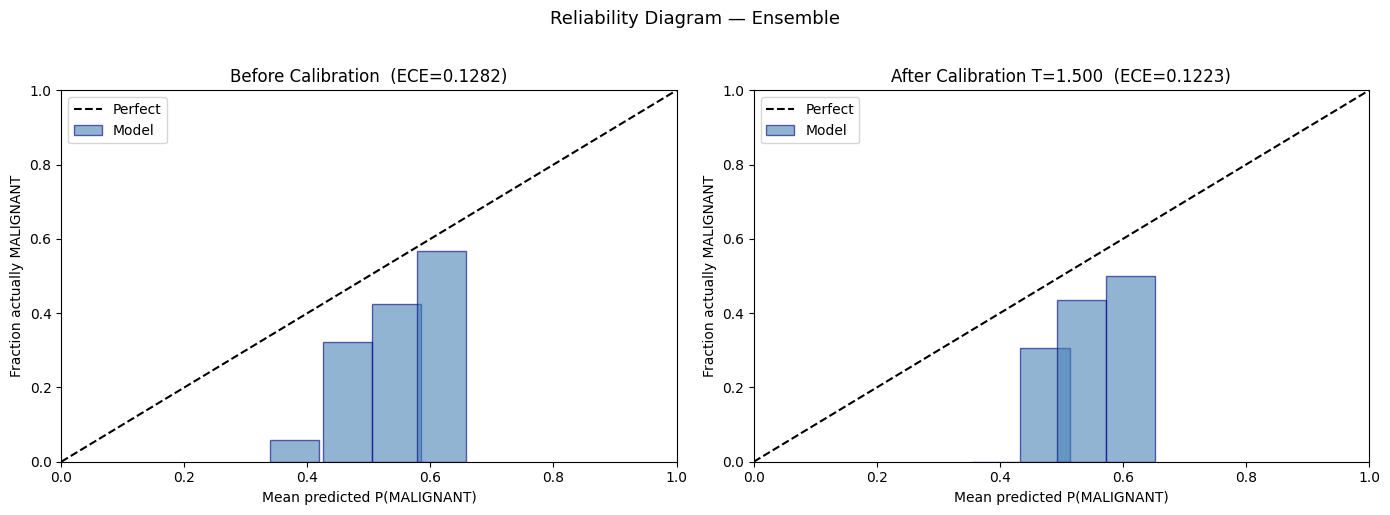

Saved → ./output/reliability_diagram.png

Saved → ./output/ensemble_predictions.csv
  Columns: true_pathology, pred_pathology, prob_malignant_raw,
           prob_malignant_cal, confidence, correct, fold1/2/3_prob


In [42]:
print("\n=== Per-fold results ===")
val_aucs, test_aucs = [], []

for r in fold_results:
    fold = r['fold']
    print(f"  Fold {fold}  |  Val  AUC={r['val']['auc']:.4f}  Acc={r['val']['acc']*100:.2f}%"
          f"  |  Test AUC={r['test']['auc']:.4f}  Acc={r['test']['acc']*100:.2f}%")
    val_aucs.append(r['val']['auc'])
    test_aucs.append(r['test']['auc'])

print(f"\n  Mean Val  AUC : {np.mean(val_aucs):.4f}  ± {np.std(val_aucs):.4f}")
print(f"  Mean Test AUC : {np.mean(test_aucs):.4f}  ± {np.std(test_aucs):.4f}")

# ── Raw ensemble (no calibration) ────────────────────────────────────────
ensemble_probs = np.mean(all_test_probs, axis=0)
true_labels    = np.array(fold_results[0]['test']['labels'])

# Use threshold 0.45 (best single-fold result was fold3 at 0.45)
ENSEMBLE_THRESHOLD = 0.45
ensemble_preds = (ensemble_probs >= ENSEMBLE_THRESHOLD).astype(int)

ens_acc = accuracy_score(true_labels, ensemble_preds)
ens_auc = roc_auc_score(true_labels, ensemble_probs)
ens_cm  = confusion_matrix(true_labels, ensemble_preds)
tn, fp, fn, tp = ens_cm.ravel()
ens_ece = compute_ece(ensemble_probs, true_labels)

ens_sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0.0
ens_precision   = tp / (tp + fp) if (tp + fp) > 0 else 0.0
ens_specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
ens_f1          = (2 * ens_precision * ens_sensitivity /
                   (ens_precision + ens_sensitivity)
                   if (ens_precision + ens_sensitivity) > 0 else 0.0)

print(f"\n=== Ensemble ({K}-fold avg)  threshold={ENSEMBLE_THRESHOLD} ===")
print(f"  Test Accuracy     : {ens_acc*100:.2f}%")
print(f"  Test AUC-ROC      : {ens_auc:.4f}")
print(f"  ECE (raw)         : {ens_ece:.4f}  ← before calibration")
print(f"  Sensitivity       : {ens_sensitivity*100:.2f}%")
print(f"  Precision         : {ens_precision*100:.2f}%")
print(f"  Specificity       : {ens_specificity*100:.2f}%")
print(f"  F1-score          : {ens_f1*100:.2f}%")
print(f"  Confusion Matrix  : TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(classification_report(true_labels, ensemble_preds,
                             target_names=['BENIGN', 'MALIGNANT'], digits=4))

# ── Temperature scaling — fit on fold 1 val, apply to ensemble ───────────
# We use fold 1 val loader as the calibration set
print("\n=== Temperature Scaling ===")
gkf_temp   = GroupKFold(n_splits=K)
splits     = list(gkf_temp.split(train_df, groups=train_df['patient_id']))
_, val_idx = splits[0]
df_val_cal = train_df.iloc[val_idx].reset_index(drop=True)
cal_loader = DataLoader(
    MammographyDataset(df_val_cal),
    batch_size=CONFIG['batch_size'], shuffle=False,
    num_workers=CONFIG['num_workers'], pin_memory=True
)

# Load fold 1 best model for temperature fitting
cal_model = build_model()
cal_model.load_state_dict(
    torch.load(f'{SAVE_DIR}/fold_1/best_model.pt',
               map_location=DEVICE, weights_only=True)
)

T = find_temperature(cal_model, cal_loader)
print(f"  Optimal temperature T = {T:.4f}")
print(f"  (T > 1 means model was overconfident — probabilities flattened)")
del cal_model
torch.cuda.empty_cache()

# Apply temperature to ensemble probabilities
# We don't have raw logits for the ensemble so we use log-odds rescaling
# as an approximation: logit(p)/T → sigmoid
def apply_temperature_to_probs(probs, T):
    """Approximate temperature scaling on probabilities via log-odds."""
    probs  = np.clip(probs, 1e-6, 1 - 1e-6)
    logits = np.log(probs / (1 - probs))   # log-odds
    scaled = logits / T
    return 1 / (1 + np.exp(-scaled))       # sigmoid

cal_probs  = apply_temperature_to_probs(ensemble_probs, T)
cal_preds  = (cal_probs >= ENSEMBLE_THRESHOLD).astype(int)
cal_ece    = compute_ece(cal_probs, true_labels)
cal_auc    = roc_auc_score(true_labels, cal_probs)
cal_cm     = confusion_matrix(true_labels, cal_preds)
tn2, fp2, fn2, tp2 = cal_cm.ravel()

cal_sensitivity = tp2 / (tp2 + fn2) if (tp2 + fn2) > 0 else 0.0
cal_precision   = tp2 / (tp2 + fp2) if (tp2 + fp2) > 0 else 0.0
cal_specificity = tn2 / (tn2 + fp2) if (tn2 + fp2) > 0 else 0.0
cal_f1          = (2 * cal_precision * cal_sensitivity /
                   (cal_precision + cal_sensitivity)
                   if (cal_precision + cal_sensitivity) > 0 else 0.0)

print(f"\n=== Calibrated Ensemble  (T={T:.3f}) ===")
print(f"  AUC-ROC           : {cal_auc:.4f}")
print(f"  ECE (calibrated)  : {cal_ece:.4f}  ← should be lower than raw ECE")
print(f"  Sensitivity       : {cal_sensitivity*100:.2f}%")
print(f"  Precision         : {cal_precision*100:.2f}%")
print(f"  Specificity       : {cal_specificity*100:.2f}%")
print(f"  F1-score          : {cal_f1*100:.2f}%")
print(f"  Confusion Matrix  : TN={tn2}  FP={fp2}  FN={fn2}  TP={tp2}")

# ── Reliability diagrams ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, probs_plot, title_plot in [
    (axes[0], ensemble_probs, f'Before Calibration  (ECE={ens_ece:.4f})'),
    (axes[1], cal_probs,      f'After Calibration T={T:.3f}  (ECE={cal_ece:.4f})'),
]:
    n_bins = 10
    bins   = np.linspace(0, 1, n_bins + 1)
    centres, accs = [], []
    for i in range(n_bins):
        mask = (probs_plot >= bins[i]) & (probs_plot < bins[i+1])
        if mask.sum() == 0:
            continue
        centres.append(probs_plot[mask].mean())
        accs.append(true_labels[mask].mean())
    ax.plot([0,1],[0,1],'k--', linewidth=1.5, label='Perfect')
    ax.bar(centres, accs, width=0.08, alpha=0.6,
           color='steelblue', edgecolor='navy', label='Model')
    ax.set_xlabel('Mean predicted P(MALIGNANT)')
    ax.set_ylabel('Fraction actually MALIGNANT')
    ax.set_title(title_plot)
    ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.legend()

plt.suptitle('Reliability Diagram — Ensemble', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/reliability_diagram.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → {SAVE_DIR}/reliability_diagram.png")

# ── Save predictions CSV with confidence scores ───────────────────────────
pred_df = pd.DataFrame({
    'image_path'         : test_df['image_path'].values[:len(true_labels)],
    'true_pathology'     : ['BENIGN' if l==0 else 'MALIGNANT' for l in true_labels],
    'pred_pathology'     : ['BENIGN' if p==0 else 'MALIGNANT' for p in ensemble_preds],
    'prob_malignant_raw' : ensemble_probs,
    'prob_malignant_cal' : cal_probs,          # calibrated probability
    'confidence'         : np.where(           # confidence = prob of predicted class
        ensemble_probs >= 0.5,
        ensemble_probs,
        1 - ensemble_probs
    ),
    'correct'            : (true_labels == ensemble_preds),
})

for fold_idx, probs in enumerate(all_test_probs, start=1):
    pred_df[f'fold{fold_idx}_prob_malignant'] = probs

pred_df.to_csv(f'{SAVE_DIR}/ensemble_predictions.csv', index=False)
print(f"\nSaved → {SAVE_DIR}/ensemble_predictions.csv")
print(f"  Columns: true_pathology, pred_pathology, prob_malignant_raw,")
print(f"           prob_malignant_cal, confidence, correct, fold1/2/3_prob")

## 12 — Plots

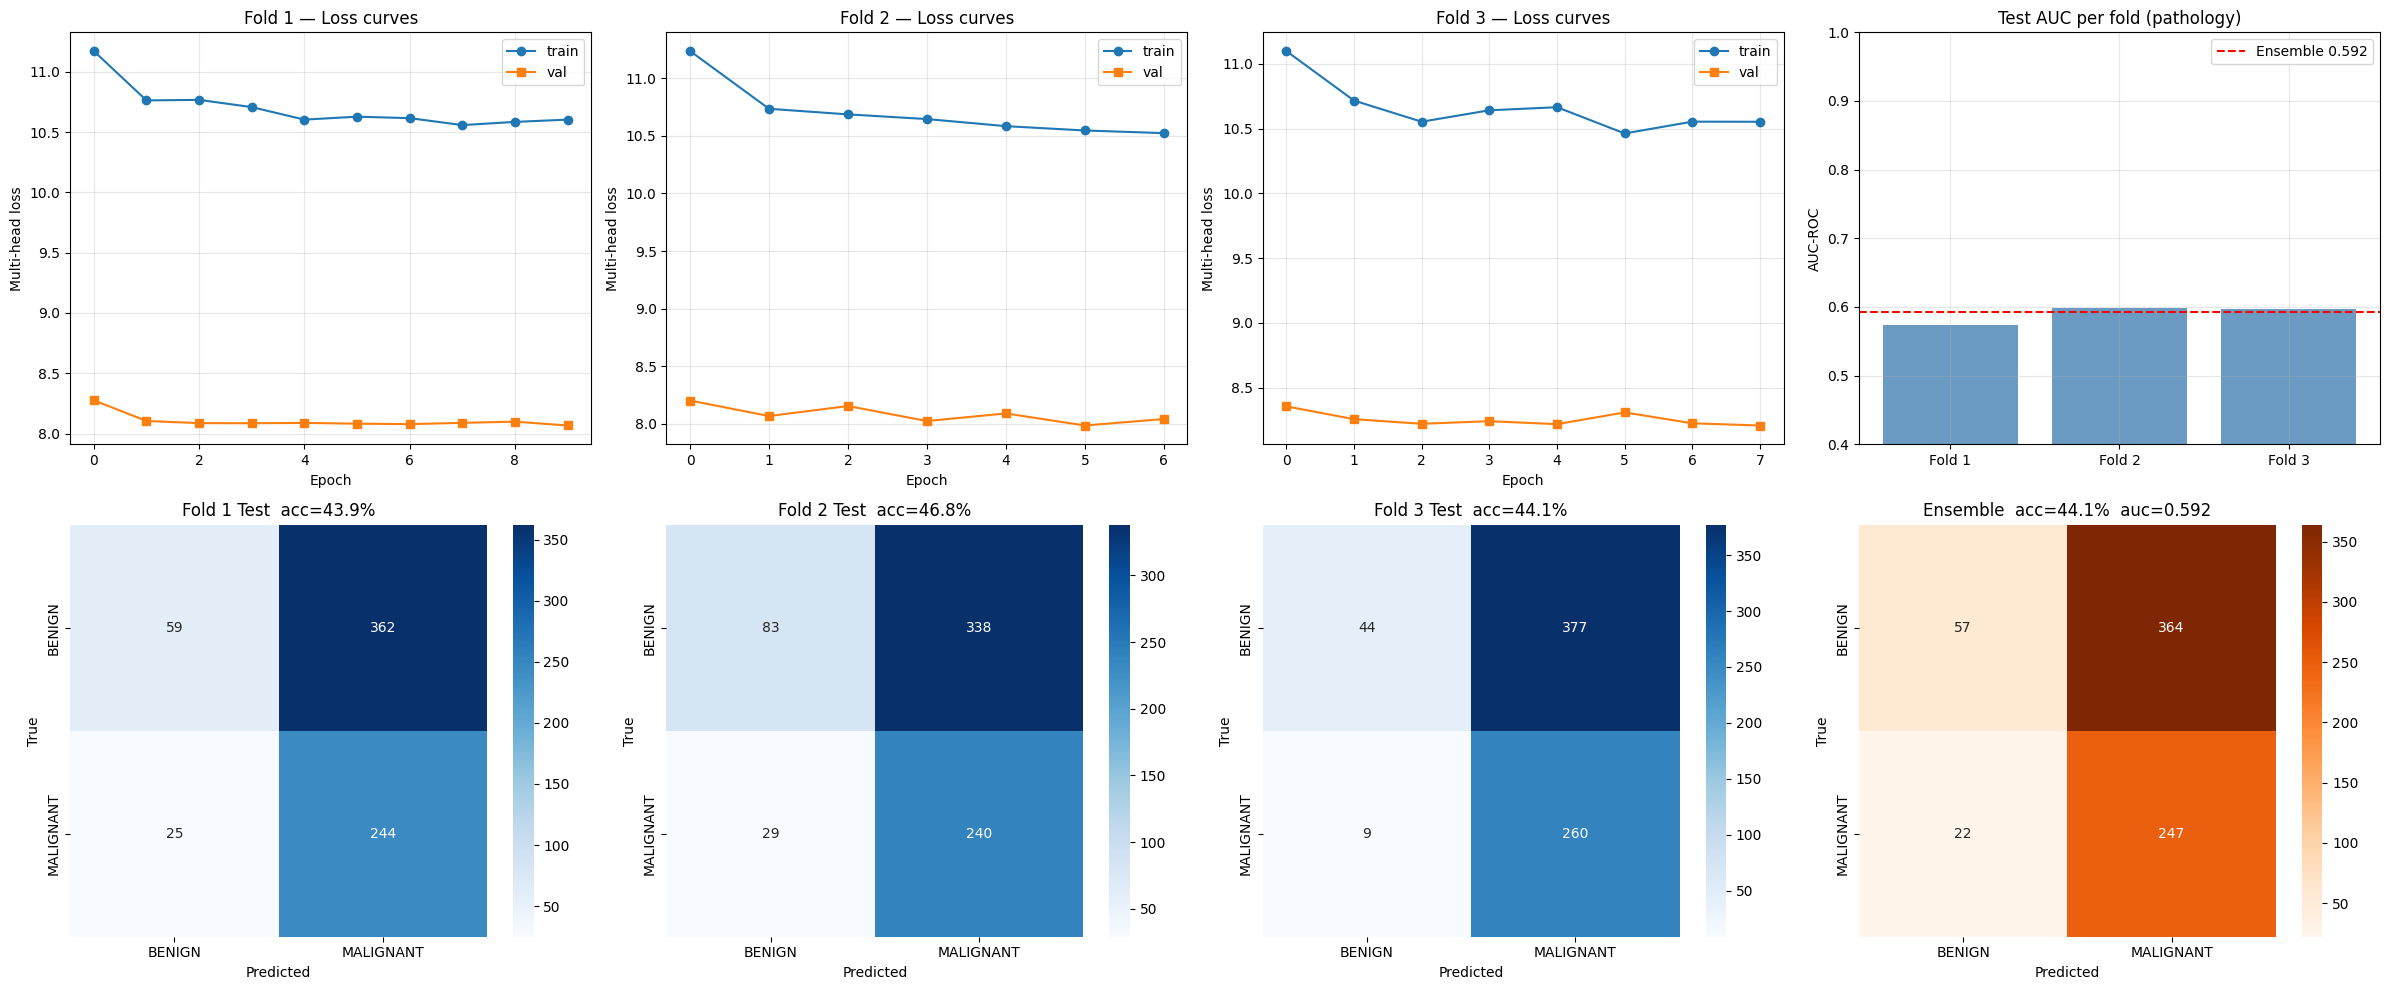

Saved → ./output/kfold_results.png


In [43]:
fig, axes = plt.subplots(2, K + 1, figsize=(6 * (K + 1), 10))

for i, (h, r) in enumerate(zip(fold_histories, fold_results)):
    ax = axes[0][i]
    ax.plot(h['train'], marker='o', label='train')
    ax.plot(h['val'],   marker='s', label='val')
    ax.set(title=f"Fold {r['fold']} — Loss curves",
           xlabel='Epoch', ylabel='Multi-head loss')
    ax.legend(); ax.grid(alpha=0.3)

ax_bar = axes[0][K]
fold_labels = [f"Fold {r['fold']}" for r in fold_results]
ax_bar.bar(fold_labels, test_aucs, color='steelblue', alpha=0.8)
ax_bar.axhline(ens_auc, color='red', linestyle='--', label=f'Ensemble {ens_auc:.3f}')
ax_bar.set(title='Test AUC per fold (pathology)', ylabel='AUC-ROC', ylim=(0.4, 1.0))
ax_bar.legend(); ax_bar.grid(alpha=0.3)

for i, r in enumerate(fold_results):
    ax = axes[1][i]
    sns.heatmap(r['test']['cm'], annot=True, fmt='d', cmap='Blues',
                xticklabels=['BENIGN', 'MALIGNANT'],
                yticklabels=['BENIGN', 'MALIGNANT'], ax=ax)
    ax.set(title=f"Fold {r['fold']} Test  acc={r['test']['acc']*100:.1f}%",
           xlabel='Predicted', ylabel='True')

sns.heatmap(ens_cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['BENIGN', 'MALIGNANT'],
            yticklabels=['BENIGN', 'MALIGNANT'], ax=axes[1][K])
axes[1][K].set(title=f"Ensemble  acc={ens_acc*100:.1f}%  auc={ens_auc:.3f}",
               xlabel='Predicted', ylabel='True')

plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/kfold_results.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → {SAVE_DIR}/kfold_results.png")

## 13 — Predict all 6 fields on new images

Drop your mammography `.jpg` files into `./new_images/` then run this cell.

In [44]:
BIRADS_DESC = {
    0: "Incomplete — additional imaging needed",
    1: "Negative — no abnormality found",
    2: "Benign finding",
    3: "Probably benign — short-interval follow-up suggested",
    4: "Suspicious — biopsy should be considered",
    5: "Highly suggestive of malignancy",
    6: "Known biopsy-proven malignancy",
}

DENSITY_DESC = {
    0: "Almost entirely fatty",
    1: "Scattered fibroglandular densities",
    2: "Heterogeneously dense",
    3: "Extremely dense",
}


@torch.no_grad()
def predict_image(image_path: str) -> dict:
    """
    Run all 6 heads on a single image using the ensemble of K fold models.
    Returns a dict with predicted class and confidence for each field.
    """
    results = {head: [] for head in HEAD_WEIGHTS}
    pathology_probs = []

    for fold in range(1, K + 1):
        model = build_model()
        ckpt_path = f'{SAVE_DIR}/fold_{fold}/best_model.pt'
        model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
        model.eval()

        try:
            image = Image.open(image_path).convert('RGB')
        except Exception as e:
            print(f"  Cannot open {image_path}: {e}")
            return None

        pixel_values = base_transform(image).unsqueeze(0).to(DEVICE)
        outputs = model(pixel_values)

        for head in HEAD_WEIGHTS:
            probs = F.softmax(outputs[head], dim=-1).cpu().numpy()[0]
            results[head].append(probs)

        pathology_probs.append(
            F.softmax(outputs['pathology'], dim=-1).cpu().numpy()[0][1]
        )
        del model
        torch.cuda.empty_cache()

    # Ensemble: average probabilities across folds
    def ensemble_head(head):
        avg_probs = np.mean(results[head], axis=0)
        pred_idx  = int(avg_probs.argmax())
        confidence = float(avg_probs.max())
        return pred_idx, confidence, avg_probs

    path_idx, path_conf, _ = ensemble_head('pathology')
    asmt_idx, asmt_conf, _ = ensemble_head('assessment')
    subt_idx, subt_conf, _ = ensemble_head('subtlety')
    dens_idx, dens_conf, _ = ensemble_head('density')
    shpe_idx, shpe_conf, _ = ensemble_head('shape')
    marg_idx, marg_conf, _ = ensemble_head('margins')

    # Decode predictions
    pathology_label = 'MALIGNANT' if path_idx == 1 else 'BENIGN'
    prob_malignant  = float(np.mean(pathology_probs))

    # Reverse-encode ordinal fields
    birads_val   = list(ASSESSMENT_MAP.keys())[asmt_idx] if asmt_idx < 7 else '?'
    subtlety_val = list(SUBTLETY_MAP.keys())[subt_idx]   if subt_idx < 5 else '?'
    density_val  = list(DENSITY_MAP.keys())[dens_idx]    if dens_idx < 4 else '?'

    shape_label   = le_shape.classes_[shpe_idx]   if shpe_idx < N_SHAPE   else 'unknown'
    margins_label = le_margins.classes_[marg_idx] if marg_idx < N_MARGINS else 'unknown'

    return {
        'image_path'     : image_path,
        'pathology'      : pathology_label,
        'prob_malignant' : round(prob_malignant, 4),
        'prob_benign'    : round(1 - prob_malignant, 4),
        'assessment'     : birads_val,
        'assessment_desc': BIRADS_DESC.get(int(birads_val), ''),
        'subtlety'       : subtlety_val,
        'breast_density' : density_val,
        'density_desc'   : DENSITY_DESC.get(dens_idx, ''),
        'mass_shape'     : shape_label,
        'mass_margins'   : margins_label,
        'path_confidence': round(path_conf, 4),
        'asmt_confidence': round(asmt_conf, 4),
    }


# ── Run on all images in new_images/ ─────────────────────────────────────
NEW_IMAGES_DIR = './new_images'
predictions = []

img_files = list(Path(NEW_IMAGES_DIR).glob('*.jpg')) + \
            list(Path(NEW_IMAGES_DIR).glob('*.png'))

if not img_files:
    print("No images found in ./new_images/ — add .jpg or .png files and re-run.")
else:
    print(f"Found {len(img_files)} image(s). Running ensemble prediction...\n")
    for img_file in img_files:
        print(f"Processing: {img_file.name}")
        result = predict_image(str(img_file))
        if result:
            predictions.append(result)
            print(f"  Pathology : {result['pathology']} (p={result['prob_malignant']:.3f})")
            print(f"  BI-RADS   : {result['assessment']} — {result['assessment_desc']}")
            print(f"  Shape     : {result['mass_shape']}")
            print(f"  Margins   : {result['mass_margins']}")
            print()

    predictions_df = pd.DataFrame(predictions)
    predictions_df.to_csv(f'{SAVE_DIR}/new_predictions.csv', index=False)
    print(f"Saved {len(predictions)} predictions → {SAVE_DIR}/new_predictions.csv")

No images found in ./new_images/ — add .jpg or .png files and re-run.


## 14 — Generate structured clinical HTML report

In [45]:
def generate_report_html(predictions: list) -> str:
    """
    Generate a radiologist-style HTML report for each predicted image.
    """
    if not predictions:
        return "<p>No predictions to report.</p>"

    report_date = datetime.now().strftime('%Y-%m-%d %H:%M')
    cases_html  = ""

    for i, p in enumerate(predictions, 1):
        img_name    = Path(p['image_path']).name
        is_mal      = p['pathology'] == 'MALIGNANT'
        path_color  = '#c0392b' if is_mal else '#1a7a4a'
        path_bg     = '#fff0f0' if is_mal else '#f0fff4'
        birads_num  = int(p['assessment']) if str(p['assessment']).isdigit() else 4
        impression  = (
            'Highly suspicious for malignancy. Tissue sampling recommended.'
            if birads_num >= 4 else
            'Probably benign. Short-interval follow-up recommended.'
            if birads_num == 3 else
            'Benign finding. Routine screening recommended.'
        )

        cases_html += f"""
        <div class="case" style="margin-bottom:40px;page-break-inside:avoid">
          <div class="case-header" style="background:#f8f9fa;border-left:4px solid {path_color};
               padding:12px 16px;border-radius:0 8px 8px 0;margin-bottom:16px">
            <span style="font-size:16px;font-weight:600">Case {i} — {img_name}</span>
            <span style="float:right;background:{path_bg};color:{path_color};
                         padding:4px 12px;border-radius:99px;font-weight:600;font-size:13px">
              {p['pathology']}
            </span>
          </div>

          <table style="width:100%;border-collapse:collapse;font-size:14px">
            <tr style="background:#f5f5f5">
              <th colspan="2" style="padding:8px 12px;text-align:left;
                  border-bottom:2px solid #ddd;font-size:13px;letter-spacing:.5px">
                CLINICAL FINDINGS
              </th>
            </tr>
            <tr>
              <td style="padding:8px 12px;color:#555;width:35%">Breast density</td>
              <td style="padding:8px 12px"><b>Category {p['breast_density']}</b> — {p['density_desc']}</td>
            </tr>
            <tr style="background:#fafafa">
              <td style="padding:8px 12px;color:#555">Lesion type</td>
              <td style="padding:8px 12px">Mass</td>
            </tr>
            <tr>
              <td style="padding:8px 12px;color:#555">Mass shape</td>
              <td style="padding:8px 12px">{p['mass_shape'].replace('-', ' ').title()}</td>
            </tr>
            <tr style="background:#fafafa">
              <td style="padding:8px 12px;color:#555">Mass margins</td>
              <td style="padding:8px 12px">{p['mass_margins'].replace('-', ' ').title()}</td>
            </tr>
            <tr>
              <td style="padding:8px 12px;color:#555">Subtlety</td>
              <td style="padding:8px 12px">{p['subtlety']} / 5</td>
            </tr>
            <tr style="background:#f5f5f5">
              <th colspan="2" style="padding:8px 12px;text-align:left;
                  border-bottom:2px solid #ddd;border-top:2px solid #ddd;
                  font-size:13px;letter-spacing:.5px">
                ASSESSMENT
              </th>
            </tr>
            <tr>
              <td style="padding:8px 12px;color:#555">BI-RADS category</td>
              <td style="padding:8px 12px">
                <b>Category {p['assessment']}</b> — {p['assessment_desc']}
              </td>
            </tr>
            <tr style="background:#fafafa">
              <td style="padding:8px 12px;color:#555">Pathology</td>
              <td style="padding:8px 12px;font-weight:600;color:{path_color}">{p['pathology']}</td>
            </tr>
            <tr>
              <td style="padding:8px 12px;color:#555">P(Malignant)</td>
              <td style="padding:8px 12px">{p['prob_malignant']:.1%} &nbsp;|
                P(Benign) {p['prob_benign']:.1%}</td>
            </tr>
            <tr style="background:#f5f5f5">
              <th colspan="2" style="padding:8px 12px;text-align:left;
                  border-bottom:2px solid #ddd;border-top:2px solid #ddd;
                  font-size:13px;letter-spacing:.5px">
                IMPRESSION
              </th>
            </tr>
            <tr>
              <td colspan="2" style="padding:10px 12px;font-style:italic">{impression}</td>
            </tr>
          </table>
          <p style="font-size:11px;color:#999;margin-top:8px">
            Model confidence — Pathology: {p['path_confidence']:.1%} &nbsp;|
            BI-RADS: {p['asmt_confidence']:.1%} &nbsp;|
            Generated by CLIP multi-output model (CBIS-DDSM fine-tuned)
          </p>
        </div>"""

    html = f"""<!DOCTYPE html>
<html lang="en"><head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Mammography Clinical Report</title>
<style>
  body {{ font-family: 'Segoe UI', Arial, sans-serif; max-width: 900px;
          margin: 40px auto; padding: 0 24px; color: #222; }}
  h1   {{ font-size: 22px; margin-bottom: 4px; }}
  .meta {{ font-size: 13px; color: #666; margin-bottom: 32px;
           padding-bottom: 16px; border-bottom: 1px solid #eee; }}
  table {{ border-bottom: 1px solid #eee; margin-bottom: 8px; }}
  @media print {{ .case {{ page-break-inside: avoid; }} }}
</style>
</head><body>
<h1>Mammography Classification Report</h1>
<div class="meta">
  Model: CLIP ViT-B/32 fine-tuned on CBIS-DDSM (mass + calcification) &nbsp;|&nbsp;
  Cross-validation: {K}-fold &nbsp;|&nbsp;
  Ensemble: averaged probabilities &nbsp;|&nbsp;
  Generated: {report_date}
</div>
{cases_html}
<p style="font-size:11px;color:#bbb;margin-top:40px;border-top:1px solid #eee;padding-top:12px">
  DISCLAIMER: This report is generated by an AI model for research purposes only.
  It should not be used as a substitute for professional medical diagnosis.
</p>
</body></html>"""
    return html


# Generate and save the report
if predictions:
    report_html  = generate_report_html(predictions)
    report_path  = f'{SAVE_DIR}/clinical_report.html'
    with open(report_path, 'w', encoding='utf-8') as f:
        f.write(report_html)
    print(f"Clinical report saved → {report_path}")
    print(f"Open it in any browser (double-click the file).")
else:
    print("No predictions found. Run cell 13 first with images in ./new_images/")

No predictions found. Run cell 13 first with images in ./new_images/


## 15 — (Optional) Generate report for the test set predictions

In [46]:
# Save ensemble test set predictions to CSV
pred_df = pd.DataFrame({
    'image_path'    : [row['image_path'] for _, row in test_df.iterrows()
                       if len(true_labels) > 0][:len(true_labels)],
    'true_pathology': ['BENIGN' if l == 0 else 'MALIGNANT' for l in true_labels],
    'pred_pathology': ['BENIGN' if p == 0 else 'MALIGNANT' for p in ensemble_preds],
    'prob_malignant': ensemble_probs,
    'correct'       : [l == p for l, p in zip(true_labels, ensemble_preds)],
})

for fold_idx, probs in enumerate(all_test_probs, start=1):
    pred_df[f'fold{fold_idx}_prob_malignant'] = probs

pred_df.to_csv(f'{SAVE_DIR}/ensemble_predictions.csv', index=False)

print(f"Saved to {SAVE_DIR}/")
print(f"  fold_N/best_model.pt         — per-fold model weights")
print(f"  kfold_results.png            — training curves + confusion matrices")
print(f"  ensemble_predictions.csv     — test set predictions")
print(f"  new_predictions.csv          — predictions on your new images")
print(f"  clinical_report.html         — structured clinical report")

Saved to ./output/
  fold_N/best_model.pt         — per-fold model weights
  kfold_results.png            — training curves + confusion matrices
  ensemble_predictions.csv     — test set predictions
  new_predictions.csv          — predictions on your new images
  clinical_report.html         — structured clinical report
